# Etapa 2 · Avaliação

| | |
|---|---|
| **Pergunta** | Como saber se um sistema resolve a tarefa, e a que custo? |
| **Entrada** | `entregas/01_dados/`: as partições e o inventário de rótulos. |
| **Entrega** | A régua do projeto (`src/especialista/avaliacao/`) e `entregas/02_avaliacao/`: resultados do piso e da linha de base, previsões guardadas, figuras e resumo. |
| **Pronto quando** | (1) os rótulos humanos, usados como previsão, tiram nota máxima; (2) a régua dá os mesmos números da conta oficial do MASSIVE; (3) o piso dá o valor que os dados preveem; (4) a linha de base está medida em qualidade e em eficiência. |

**Artigos-âncora**

- Métricas: FitzGerald et al., *MASSIVE* ([arXiv 2204.08582](https://arxiv.org/abs/2204.08582)).
- Incerteza: Koehn, *Statistical Significance Tests for Machine Translation Evaluation* (EMNLP 2004); Berg-Kirkpatrick et al., *An Empirical Investigation of Statistical Significance in NLP* (EMNLP 2012).
- Eficiência: Reddi et al., *MLPerf Inference Benchmark* ([arXiv 1911.02549](https://arxiv.org/abs/1911.02549)); Dehghani et al., *The Efficiency Misnomer* ([arXiv 2110.12894](https://arxiv.org/abs/2110.12894)).

**Por que esta etapa vem antes de qualquer modelo.** Se a régua for definida depois, ela acaba moldada pelo modelo que se quer defender. Definida agora, todos os sistemas do projeto, da LLM ao modelo quantizado, passam pela mesma medida.

**Roteiro**

1. O contrato: o que um sistema devolve
2. Régua de qualidade: quatro métricas
3. A régua está certa?
4. Piso e linha de base
5. Incerteza: o que este conjunto consegue distinguir
6. Uma decisão tomada do jeito certo
7. Onde a linha de base erra
8. Régua de eficiência
9. Resultado no teste
10. Entrega
11. Resposta

In [1]:
import json
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import Previsao, carregar_previsoes, ouro, salvar_previsoes
from especialista.avaliacao.referencia import avaliar_como_massive, corromper
from especialista.bio import bio_para_rotulos, bio_para_spans, rotulos_para_spans, spans_para_bio
from especialista.caminhos import RAIZ, entrega
from especialista.dados import massive
from especialista.modelos.linha_de_base import LinhaDeBase, Piso

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 120)

PASTA = entrega("02_avaliacao")

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
ouro_dev, ouro_teste = ouro(dev), ouro(teste)


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    """Número com vírgula decimal: 2.46 -> 2,5."""
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    """Fração como pontos percentuais: 0.8457 -> 84,6."""
    return num(100 * x, casas)


def dif(x):
    """Diferença em pontos percentuais, com sinal: 0.0246 -> +2,5."""
    return f"{100 * x:+.1f}".replace(".", ",")


def tabela_pts(df):
    """Mostra frações como pontos percentuais com uma casa."""
    return df.map(lambda v: pts(v) if isinstance(v, float) else v)


print(f"Treino: {n(len(treino))}   Validação (dev): {n(len(dev))}   Teste: {n(len(teste))}")

Treino: 11.514   Validação (dev): 2.033   Teste: 2.974


## 1. O contrato: o que um sistema devolve

Para a régua, um sistema é qualquer coisa que recebe o **texto** do enunciado e devolve uma `Previsao`:

- `intent`: a intenção;
- `slots`: as entidades, cada uma como `(tipo, início, fim)`, em posições de palavra.

A régua não sabe se quem respondeu foi uma tabela, uma rede ou uma LLM. É isso que permite comparar todos na mesma medida.

In [2]:
exemplo = treino[treino["n_slots"] >= 3].iloc[0]
certo = Previsao.de_tags(exemplo.intent, exemplo.tags)

print("Entrada:  ", repr(exemplo.utt))
print("Resposta: ", certo)
display(HTML(visual.html_bio(exemplo.tokens, exemplo.tags)))

Entrada:   'procura por comida tailandesa com takeaway perto do centro do porto'
Resposta:  Previsao(intent='takeaway_query', slots=(('food_type', 2, 4), ('order_type', 5, 6), ('place_name', 8, 11)))


## 2. Régua de qualidade: quatro métricas

| Métrica | Pergunta que responde | Como se calcula |
|---|---|---|
| **Acurácia de intenção** | Em quantos enunciados a intenção está certa? | acertos ÷ enunciados |
| **Macro-F1 de intenção** | E se cada intenção pesar igual, rara ou frequente? | F1 de cada intenção, depois a média simples |
| **F1 de entidades** | Das entidades, quantas saíram com tipo e limites certos? | precisão e recall sobre entidades inteiras, somadas em todos os enunciados |
| **Exact match** | Em quantos enunciados a resposta inteira está certa? | intenção certa **e** conjunto de entidades idêntico |

A acurácia de intenção, o F1 de entidades e o exact match são as três métricas do artigo do MASSIVE. O macro-F1 entra por causa do desbalanceamento medido na Etapa 1 (810 exemplos na maior intenção, 4 na menor).

O exact match é a que mais importa para um agente: se a intenção ou um argumento sai errado, a chamada da ferramenta sai errada.

### Um enunciado, cinco respostas

Para ver o que cada métrica pune, cinco respostas possíveis para o enunciado acima.

In [3]:
entidades = list(certo.slots)
longa = next(i for i, (_, ini, fim) in enumerate(entidades) if fim - ini > 1)  # uma entidade com mais de uma palavra
assert "meal_type" in rotulos["slot_types"] and entidades[0][0] != "meal_type"
assert "takeaway_order" in rotulos["intents"] and certo.intent != "takeaway_order"


def trocar(i, nova):
    return tuple(nova if j == i else e for j, e in enumerate(entidades))


tipo, ini, fim = entidades[longa]
respostas = {
    "Tudo certo": certo,
    "Limite errado": Previsao(certo.intent, trocar(longa, (tipo, ini, fim - 1))),
    "Tipo errado": Previsao(certo.intent, trocar(0, ("meal_type", *entidades[0][1:]))),
    "Entidade esquecida": Previsao(certo.intent, tuple(e for j, e in enumerate(entidades) if j != 1)),
    "Intenção errada": Previsao("takeaway_order", certo.slots),
}

tags_certas = list(exemplo.tags)
linhas = []
for nome, resposta in respostas.items():
    tags = spans_para_bio(list(resposta.slots), len(exemplo.tokens))
    display(HTML(
        f'<div style="font-size:12px;margin-top:10px;"><b>{nome}</b> '
        f'<span style="font-family:monospace;">intent = {resposta.intent}</span></div>'
        + visual.html_bio(exemplo.tokens, tags)
    ))
    notas = qualidade.avaliar([certo], [resposta])
    linhas.append({
        "resposta": nome,
        "intenção certa": "sim" if resposta.intent == certo.intent else "não",
        "entidades certas": f"{len(set(resposta.slots) & set(certo.slots))} de {len(certo.slots)}",
        "acerto por palavra": pts(np.mean([a == b for a, b in zip(tags, tags_certas)]), 0) + "%",
        "F1 de entidades": pts(notas["slot_f1"], 0),
        "exact match": "sim" if notas["exact_match"] == 1 else "não",
    })
cinco = pd.DataFrame(linhas).set_index("resposta")
cinco

,intenção certa,entidades certas,acerto por palavra,F1 de entidades,exact match
resposta,,,,,
Tudo certo,sim,3 de 3,100%,100,sim
Limite errado,sim,2 de 3,91%,67,não
Tipo errado,sim,2 de 3,82%,67,não
Entidade esquecida,sim,2 de 3,91%,80,não
Intenção errada,não,3 de 3,100%,100,não


**Leitura.**

- Em "Limite errado", quase todas as palavras estão com a tag certa, mas a entidade não serve: um argumento cortado é um argumento errado. Por isso a régua conta **entidades inteiras**, não palavras.
- Uma entidade com limite ou tipo errado custa duas vezes: é uma entidade prevista que não existe (cai a precisão) e uma entidade real que faltou (cai o recall).
- Só a primeira resposta passa no exact match. Ele é a métrica mais dura e a mais próxima do uso real.

## 3. A régua está certa?

Uma métrica com erro contamina todas as etapas seguintes sem dar sinal. Dois testes, antes de medir qualquer sistema.

### 3.1 O oráculo

Se a previsão for o próprio rótulo humano, toda métrica tem de dar 100.

In [4]:
oraculo = qualidade.avaliar(ouro_dev, ouro_dev)
oraculo_ok = all(v == 1.0 for v in oraculo.values())
pd.Series({qualidade.NOMES[m]: pts(v) for m, v in oraculo.items()}, name="oráculo em dev").to_frame()

,oráculo em dev
Acurácia de intenção,"100,0"
Macro-F1 de intenção,"100,0"
Precisão de entidades,"100,0"
Recall de entidades,"100,0"
F1 de entidades,"100,0"
Exact match,"100,0"


### 3.2 A conta oficial

O código de avaliação do MASSIVE calcula o F1 de entidades com a biblioteca `seqeval` e o exact match comparando intenção e sequência inteira. A nossa régua faz a conta por conta própria, sobre spans, para servir também a uma LLM que devolve trechos de texto. As duas precisam dar o mesmo número.

O teste: estragar ao acaso uma fração dos rótulos de `dev`, o que gera "previsões" com todo tipo de erro, e medir pelas duas contas.

In [5]:
# A conta oficial usa rótulos simples por palavra. Antes, conferir que essa forma não perde nada nos nossos dados.
sem_perda = all(
    rotulos_para_spans(bio_para_rotulos(tags)) == bio_para_spans(tags)
    for parte in particoes.values() for tags in parte["tags"]
)

base = [(intent, bio_para_rotulos(tags)) for intent, tags in zip(dev["intent"], dev["tags"])]
linhas = []
for taxa in (0.05, 0.20, 0.50):
    ruidoso = corromper(base, taxa, rotulos["intents"], rotulos["slot_types"], semente=0)
    oficial = avaliar_como_massive(base, ruidoso)
    nossa = qualidade.avaliar(ouro_dev, [Previsao.de_rotulos(i, r) for i, r in ruidoso])
    for metrica, valor in oficial.items():
        linhas.append({
            "rótulos estragados": f"{taxa:.0%}",
            "métrica": qualidade.NOMES[metrica],
            "conta oficial": valor,
            "nossa régua": nossa[metrica],
            "diferença": abs(valor - nossa[metrica]),
        })
conferencia = pd.DataFrame(linhas)
maior_diferenca = conferencia["diferença"].max()

print(f"Rótulos simples equivalem ao BIO nos nossos dados: {'sim' if sem_perda else 'NÃO'}")
print(f"Maior diferença entre as duas contas: {maior_diferenca:.1e}" if maior_diferenca else "Maior diferença entre as duas contas: 0")
conferencia.set_index(["rótulos estragados", "métrica"]).map(lambda v: f"{v:.6f}" if v > 1e-9 else "0")

Rótulos simples equivalem ao BIO nos nossos dados: sim
Maior diferença entre as duas contas: 5.6e-17


conta oficial nossa régua diferença
rótulos estragados métrica                                                 
5%                 Acurácia de intenção      0.949336    0.949336         0
                   Macro-F1 de intenção      0.915353    0.915353         0
                   F1 de entidades           0.796838    0.796838         0
                   Exact match               0.674865    0.674865         0
20%                Acurácia de intenção      0.798819    0.798819         0
                   Macro-F1 de intenção      0.727112    0.727112         0
                   F1 de entidades           0.420244    0.420244         0
                   Exact match               0.197245    0.197245         0
50%                Acurácia de intenção      0.517954    0.517954         0
                   Macro-F1 de intenção      0.443818    0.443818         0
                   F1 de entidades           0.146682    0.146682         0
                   Exact match               0.028529    0.028529         0

## 4. Piso e linha de base

Dois sistemas simples, nenhum deles uma rede neural. Eles provam que a régua funciona de ponta a ponta e dão o ponto de partida do projeto.

| Sistema | Intenção | Entidades |
|---|---|---|
| **Piso** | sempre a intenção mais comum do treino | nenhuma |
| **Linha de base (palavras)** | TF-IDF de palavras + regressão logística | cada palavra recebe o rótulo que mais teve no treino |
| **Linha de base (palavras + caracteres)** | a mesma, somando n-gramas de 2 a 5 caracteres | igual |

A linha de base é um saco de palavras: não usa ordem nem contexto. O que ela não alcançar é o que uma arquitetura de verdade precisa justificar.

Os hiperparâmetros são fixos, sem busca. Todas as medidas desta seção são em `dev`; o teste só é aberto na seção 9.

In [6]:
piso = Piso().treinar(treino)
base_a = LinhaDeBase(caracteres=False).treinar(treino)
base_b = LinhaDeBase(caracteres=True).treinar(treino)

prev_dev = {s.nome: s.prever(list(dev["utt"])) for s in (piso, base_a, base_b)}
em_dev = pd.DataFrame({nome: qualidade.avaliar(ouro_dev, prev) for nome, prev in prev_dev.items()}).T
em_dev = em_dev[list(qualidade.METRICAS)].rename(columns=qualidade.NOMES)
tabela_pts(em_dev)

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
Piso (classe majoritária),"6,4","0,2","0,0","0,7"
Linha de base (palavras),"82,0","79,2","49,9","43,6"
Linha de base (palavras + caracteres),"84,5","82,0","49,9","45,1"


O piso também serve de teste da régua, porque o resultado dele se calcula direto dos dados, sem passar por ela:

- a acurácia tem de ser a fração de `dev` que tem a intenção mais comum do treino;
- o exact match tem de ser a fração de `dev` que tem essa intenção **e** nenhuma entidade.

In [7]:
majoritaria = piso.intent
esperado = {
    "intent_acc": (dev["intent"] == majoritaria).mean(),
    "exact_match": ((dev["intent"] == majoritaria) & (dev["n_slots"] == 0)).mean(),
    "slot_f1": 0.0,
}
medido = qualidade.avaliar(ouro_dev, prev_dev[piso.nome])
piso_ok = all(abs(medido[m] - v) < 1e-12 for m, v in esperado.items())

print(f"Intenção mais comum no treino: {majoritaria}")
pd.DataFrame({
    "previsto pelos dados": {qualidade.NOMES[m]: pts(v, 2) for m, v in esperado.items()},
    "medido pela régua": {qualidade.NOMES[m]: pts(medido[m], 2) for m in esperado},
})

Intenção mais comum no treino: calendar_set


,previsto pelos dados,medido pela régua
Acurácia de intenção,"6,44","6,44"
Exact match,"0,69","0,69"
F1 de entidades,"0,00","0,00"


## 5. Incerteza: o que este conjunto consegue distinguir

Um número medido em 2 mil enunciados não é exato: com outros 2 mil enunciados do mesmo tipo, sairia um pouco diferente. O **bootstrap** estima esse "um pouco":

1. sorteia-se um novo conjunto do mesmo tamanho, com reposição, a partir dos enunciados de `dev`;
2. recalculam-se as métricas;
3. repete-se 2.000 vezes; o intervalo que contém 95% dos resultados é o intervalo de confiança.

O sorteio é por **enunciado**, nunca por palavra, porque as palavras de um mesmo enunciado não são independentes.

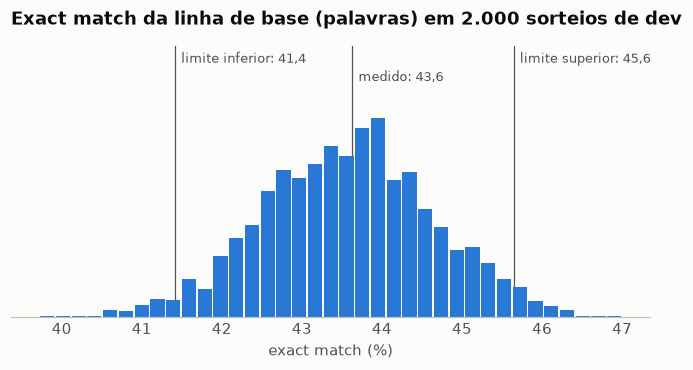

In [8]:
amostras = qualidade.reamostrar(ouro_dev, prev_dev[base_a.nome])
ic = qualidade.intervalo(ouro_dev, prev_dev[base_a.nome])

fig, ax = visual.histograma(
    100 * amostras["exact_match"],
    "Exact match da linha de base (palavras) em 2.000 sorteios de dev",
    "exact match (%)",
    marcas={
        f"limite inferior: {pts(ic.loc['exact_match', 'ic_min'])}": 100 * ic.loc["exact_match", "ic_min"],
        f"medido: {pts(ic.loc['exact_match', 'valor'])}": 100 * ic.loc["exact_match", "valor"],
        f"limite superior: {pts(ic.loc['exact_match', 'ic_max'])}": 100 * ic.loc["exact_match", "ic_max"],
    },
    passo=100 / len(dev),
)
visual.salvar(fig, PASTA, "bootstrap")
plt.show()

In [9]:
margem = (ic["ic_max"] - ic["ic_min"]) / 2
# Para comparação: a fórmula do artigo do MASSIVE (aproximação normal), que vale para proporções.
normal = {m: 1.96 * np.sqrt(ic.loc[m, "valor"] * (1 - ic.loc[m, "valor"]) / len(dev)) for m in ("intent_acc", "exact_match")}

resolucao = pd.DataFrame({
    "medido": ic["valor"].map(pts),
    "intervalo de 95%": [f"{pts(a)} a {pts(b)}" for a, b in zip(ic["ic_min"], ic["ic_max"])],
    "margem (±)": margem.map(pts),
    "margem pela fórmula normal": [pts(normal[m]) if m in normal else "n/a" for m in ic.index],
}).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES)
display(resolucao)

display(Markdown(f"""
**Leitura.**

- Em `dev` ({n(len(dev))} enunciados), a acurácia de intenção vem com margem de ±{pts(margem['intent_acc'])} pontos e o exact match com ±{pts(margem['exact_match'])}. Diferenças menores que isso entre dois sistemas não se distinguem olhando os dois números lado a lado.
- Para proporções, o bootstrap e a fórmula normal usada no artigo do MASSIVE concordam (±{pts(margem['intent_acc'])} contra ±{pts(normal['intent_acc'])} na intenção). O bootstrap tem a vantagem de servir também para F1, que não é proporção.
- O macro-F1 é a métrica mais instável (±{pts(margem['intent_macro_f1'])}), porque depende de intenções com pouquíssimos exemplos.
"""))

,medido,intervalo de 95%,margem (±),margem pela fórmula normal
Acurácia de intenção,"82,0","80,4 a 83,6","1,6","1,7"
Macro-F1 de intenção,"79,2","76,2 a 81,9","2,9",n/a
F1 de entidades,"49,9","47,8 a 52,1","2,1",n/a
Exact match,"43,6","41,4 a 45,6","2,1","2,2"



**Leitura.**

- Em `dev` (2.033 enunciados), a acurácia de intenção vem com margem de ±1,6 pontos e o exact match com ±2,1. Diferenças menores que isso entre dois sistemas não se distinguem olhando os dois números lado a lado.
- Para proporções, o bootstrap e a fórmula normal usada no artigo do MASSIVE concordam (±1,6 contra ±1,7 na intenção). O bootstrap tem a vantagem de servir também para F1, que não é proporção.
- O macro-F1 é a métrica mais instável (±2,9), porque depende de intenções com pouquíssimos exemplos.


## 6. Uma decisão tomada do jeito certo

A Etapa 1 mostrou que 4,0% das palavras do teste nunca aparecem no treino, e levantou a hipótese de que olhar dentro da palavra ajuda. A linha de base permite testar isso agora, e serve de ensaio para o procedimento que todas as etapas vão seguir:

1. **A regra vem antes do resultado.** Adota-se a versão com caracteres só se o intervalo de 95% da diferença de acurácia de intenção ficar todo acima de zero. Caso contrário, fica a mais simples.
2. **A decisão é tomada em `dev`.** O teste não participa.
3. **A comparação é pareada.** Os dois sistemas são medidos nos mesmos sorteios, e o que se analisa é a diferença em cada sorteio. Isso remove a parte da variação que é comum aos dois e enxerga diferenças menores do que as margens da seção 5.

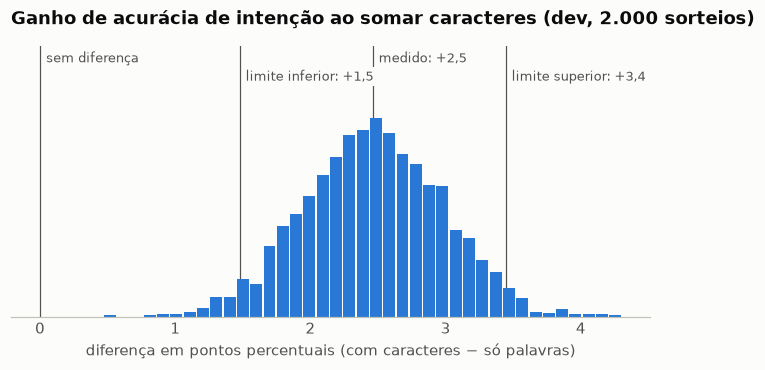

,só palavras,palavras + caracteres,diferença,intervalo de 95% da diferença,distinguível
Acurácia de intenção,"82,0","84,5","+2,5","+1,5 a +3,4",sim
Macro-F1 de intenção,"79,2","82,0","+2,8","+1,6 a +4,4",sim
F1 de entidades,"49,9","49,9","+0,0","+0,0 a +0,0",não
Exact match,"43,6","45,1","+1,4","+0,7 a +2,1",sim


In [10]:
comparacao = qualidade.comparar(ouro_dev, prev_dev[base_a.nome], prev_dev[base_b.nome])
diferencas = qualidade.reamostrar(ouro_dev, prev_dev[base_b.nome]) - qualidade.reamostrar(ouro_dev, prev_dev[base_a.nome])

d = comparacao.loc["intent_acc"]
fig, ax = visual.histograma(
    100 * diferencas["intent_acc"],
    "Ganho de acurácia de intenção ao somar caracteres (dev, 2.000 sorteios)",
    "diferença em pontos percentuais (com caracteres − só palavras)",
    marcas={
        "sem diferença": 0.0,
        f"limite inferior: {dif(d['ic_min'])}": 100 * d["ic_min"],
        f"medido: {dif(d['diferenca'])}": 100 * d["diferenca"],
        f"limite superior: {dif(d['ic_max'])}": 100 * d["ic_max"],
    },
    passo=100 / len(dev),
)
visual.salvar(fig, PASTA, "decisao_caracteres")
plt.show()

vista = comparacao.loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES)
pd.DataFrame({
    "só palavras": vista["a"].map(pts),
    "palavras + caracteres": vista["b"].map(pts),
    "diferença": vista["diferenca"].map(dif),
    "intervalo de 95% da diferença": [f"{dif(a)} a {dif(b)}" for a, b in zip(vista["ic_min"], vista["ic_max"])],
    "distinguível": vista["distinguivel"].map({True: "sim", False: "não"}),
})

In [11]:
adotar_caracteres = bool(d["ic_min"] > 0)
linha_de_base = base_b if adotar_caracteres else base_a

display(Markdown(f"""
**Decisão.** O intervalo da diferença de acurácia de intenção vai de {dif(d['ic_min'])} a {dif(d['ic_max'])} pontos{", todo acima de zero" if adotar_caracteres else " e inclui zero"}. Pela regra, a linha de base do projeto é **{linha_de_base.nome}**.

O F1 de entidades não muda, como esperado: as duas versões usam a mesma tabela de palavras para as entidades.
"""))


**Decisão.** O intervalo da diferença de acurácia de intenção vai de +1,5 a +3,4 pontos, todo acima de zero. Pela regra, a linha de base do projeto é **Linha de base (palavras + caracteres)**.

O F1 de entidades não muda, como esperado: as duas versões usam a mesma tabela de palavras para as entidades.


## 7. Onde a linha de base erra

Saber onde o sistema mais simples falha diz o que a arquitetura da Etapa 3 precisa resolver.

### 7.1 Intenção: as classes raras

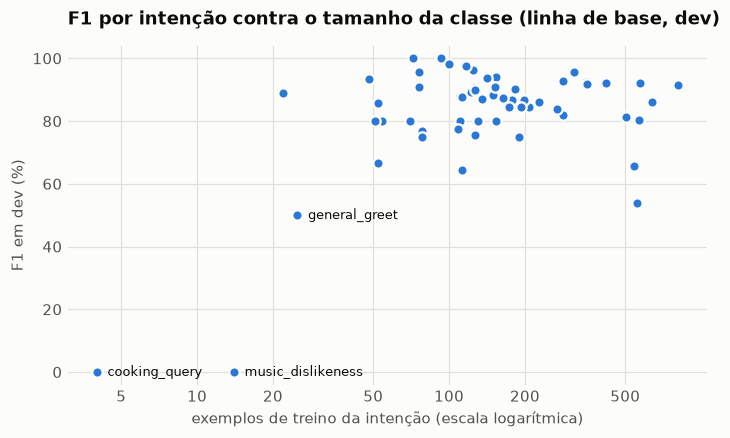


**Leitura.** Cada ponto é uma intenção (59 das 60 aparecem em dev). As 17 intenções com menos de 100 exemplos de treino têm F1 médio de 73,1; as 42 com 100 ou mais, 85,6. A acurácia (84,5) esconde isso, porque as classes raras pesam pouco nela; o macro-F1 (82,0) mostra.


In [12]:
por_classe = qualidade.por_intencao(ouro_dev, prev_dev[linha_de_base.nome])
por_classe["exemplos de treino"] = treino["intent"].value_counts().reindex(por_classe.index)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(por_classe["exemplos de treino"], 100 * por_classe["f1"], s=46, color=visual.AZUL,
           edgecolor=visual.SUPERFICIE, linewidth=1.5)
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])
ax.minorticks_off()
ax.set_ylim(-4, 104)
ax.grid(True)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.set_title("F1 por intenção contra o tamanho da classe (linha de base, dev)")
ax.set_xlabel("exemplos de treino da intenção (escala logarítmica)")
ax.set_ylabel("F1 em dev (%)")
for intent, linha in por_classe.nsmallest(3, "f1").iterrows():
    ax.annotate(intent, (linha["exemplos de treino"], 100 * linha["f1"]), xytext=(7, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=visual.TINTA)
visual.salvar(fig, PASTA, "f1_por_intencao")
plt.show()

medido_base = qualidade.avaliar(ouro_dev, prev_dev[linha_de_base.nome])
pequenas = por_classe[por_classe["exemplos de treino"] < 100]
grandes = por_classe[por_classe["exemplos de treino"] >= 100]
display(Markdown(f"""
**Leitura.** Cada ponto é uma intenção ({len(por_classe)} das 60 aparecem em dev). As {len(pequenas)} intenções com menos de 100 exemplos de treino têm F1 médio de {pts(pequenas['f1'].mean())}; as {len(grandes)} com 100 ou mais, {pts(grandes['f1'].mean())}. A acurácia ({pts(medido_base['intent_acc'])}) esconde isso, porque as classes raras pesam pouco nela; o macro-F1 ({pts(medido_base['intent_macro_f1'])}) mostra.
"""))

### 7.2 Entidades: falta contexto

A linha de base rotula cada palavra sozinha. Dois enunciados de `dev` em que ela acerta a intenção e erra as entidades:

In [13]:
previstos = prev_dev[linha_de_base.nome]
casos = [
    i for i, (o, p) in enumerate(zip(ouro_dev, previstos))
    if o.intent == p.intent and set(o.slots) != set(p.slots) and len(o.slots) >= 2 and len(dev.iloc[i].tokens) <= 10
][:2]
for i in casos:
    linha = dev.iloc[i]
    display(HTML(
        f'<div style="font-size:12px;margin-top:12px;"><b>Rótulo humano</b></div>'
        + visual.html_bio(linha.tokens, linha.tags)
        + '<div style="font-size:12px;"><b>Linha de base</b></div>'
        + visual.html_bio(linha.tokens, spans_para_bio(list(previstos[i].slots), len(linha.tokens)))
    ))

display(Markdown(f"""
**Leitura.** A linha de base faz {pts(medido_base['slot_f1'])} de F1 de entidades, com precisão de {pts(medido_base['slot_precision'])} e recall de {pts(medido_base['slot_recall'])}. Sem contexto, a mesma palavra recebe sempre o mesmo rótulo, e os limites das entidades saem quebrados. É a parte da tarefa em que a arquitetura tem mais a ganhar.
"""))


**Leitura.** A linha de base faz 49,9 de F1 de entidades, com precisão de 46,5 e recall de 53,8. Sem contexto, a mesma palavra recebe sempre o mesmo rótulo, e os limites das entidades saem quebrados. É a parte da tarefa em que a arquitetura tem mais a ganhar.


## 8. Régua de eficiência

Qualidade é metade da pergunta. A outra metade é quanto custa obter a resposta.

**Protocolo de latência**, inspirado no cenário single-stream do MLPerf Inference:

- uma consulta por vez (batch 1), em sequência, como um agente chamando o subagente;
- o relógio cobre tudo o que o sistema faz com o texto, da separação das palavras à resposta montada;
- 50 chamadas de aquecimento, depois 1.024 consultas medidas;
- reportam-se percentis (p50, p95, p99), porque a média esconde a cauda.

Junto vão o **número de parâmetros**, o **tamanho em disco** e a **máquina**. Dehghani et al. mostram que parâmetros, operações e tempo ordenam os mesmos modelos de formas diferentes; por isso o projeto reporta os três e nunca um só.

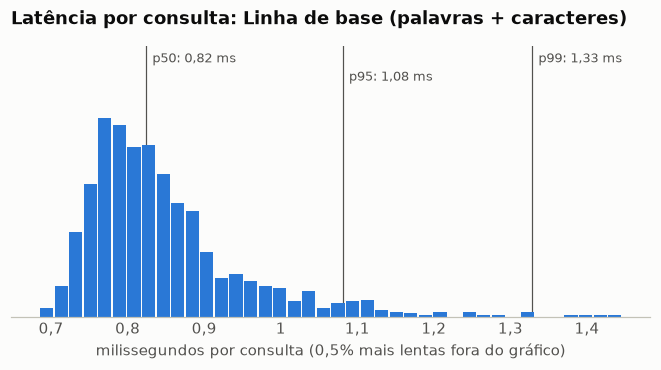

Máquina: {'cpu': '13th Gen Intel(R) Core(TM) i7-13700K', 'cpus_logicas': 24, 'plataforma': 'WSL2', 'python': '3.12.13'}


,p50 (ms),p95 (ms),p99 (ms),parâmetros,tamanho em disco (MB)
Piso (classe majoritária),"0,0003","0,0003","0,0004",1,"0,0"
Linha de base (palavras + caracteres),"0,8242","1,0811","1,3286",3.940.300,"33,0"


In [14]:
consultas = list(dev["utt"])
tempos = {s.nome: eficiencia.medir_latencia(s, consultas) for s in (piso, linha_de_base)}
maquina = eficiencia.ambiente()

t = tempos[linha_de_base.nome]
resumo_lat = eficiencia.resumir_latencia(t)
corte = np.percentile(t, 99.5)
fig, ax = visual.histograma(
    t[t <= corte],
    f"Latência por consulta: {linha_de_base.nome}",
    "milissegundos por consulta (0,5% mais lentas fora do gráfico)",
    marcas={
        f"p50: {num(resumo_lat['latencia_p50_ms'], 2)} ms": resumo_lat["latencia_p50_ms"],
        f"p95: {num(resumo_lat['latencia_p95_ms'], 2)} ms": resumo_lat["latencia_p95_ms"],
        f"p99: {num(resumo_lat['latencia_p99_ms'], 2)} ms": resumo_lat["latencia_p99_ms"],
    },
)
visual.salvar(fig, PASTA, "latencia")
plt.show()

print("Máquina:", maquina)
custo = pd.DataFrame({
    s.nome: {
        "p50 (ms)": num(eficiencia.resumir_latencia(tempos[s.nome])["latencia_p50_ms"], 4),
        "p95 (ms)": num(eficiencia.resumir_latencia(tempos[s.nome])["latencia_p95_ms"], 4),
        "p99 (ms)": num(eficiencia.resumir_latencia(tempos[s.nome])["latencia_p99_ms"], 4),
        "parâmetros": n(s.parametros),
        "tamanho em disco (MB)": num(eficiencia.bytes_em_disco(s) / 1e6, 1),
    }
    for s in (piso, linha_de_base)
}).T
custo

**Limites desta medida.**

- A máquina roda Linux dentro do WSL2. Ali não há como garantir que o processo fique nos núcleos de desempenho do processador, e isso afeta os percentis altos.
- Latência varia com a carga da máquina no momento. Na etapa de comparativo, todos os sistemas serão medidos de novo, na mesma sessão.
- "Parâmetros" de uma regressão logística sobre TF-IDF e de uma rede não são a mesma coisa. O número serve para ordem de grandeza.

## 9. Resultado no teste

Só agora o teste é aberto, uma vez, com as decisões já tomadas em `dev`. É a regra para todas as etapas: **decide-se em `dev`, reporta-se em teste.**

As linhas "publicado" são do artigo do MASSIVE, no mesmo conjunto de teste. Uma diferença a ter em mente: aqueles modelos treinaram com os 51 idiomas juntos, e os deste projeto treinam só com pt-PT.

In [15]:
prev_teste = {s.nome: s.prever(list(teste["utt"])) for s in (piso, linha_de_base)}

linhas = []
for s in (piso, linha_de_base):
    for particao, rotulos_humanos, prev in (("dev", ouro_dev, prev_dev[s.nome]), ("test", ouro_teste, prev_teste[s.nome])):
        linhas.append(resultados.registrar(
            s.nome, particao, rotulos_humanos, prev,
            tempos_ms=tempos[s.nome], parametros=s.parametros, bytes_em_disco=eficiencia.bytes_em_disco(s),
        ))
tabela = pd.DataFrame(linhas)
no_teste = tabela[tabela["particao"] == "test"].set_index("sistema")


def com_margem(linha, metrica):
    return f"{pts(linha[metrica])} ({pts(linha[metrica + '_ic_min'])} a {pts(linha[metrica + '_ic_max'])})"


final = pd.DataFrame({
    sistema: {
        "Acurácia de intenção": com_margem(linha, "intent_acc"),
        "Macro-F1 de intenção": com_margem(linha, "intent_macro_f1"),
        "F1 de entidades": com_margem(linha, "slot_f1"),
        "Exact match": com_margem(linha, "exact_match"),
        "Parâmetros": n(linha["parametros"]),
    }
    for sistema, linha in no_teste.iterrows()
}).T
for nome, ref in massive.REFERENCIA.items():
    final.loc[f"{nome} (publicado)"] = {
        "Acurácia de intenção": f"{num(ref['intent_acc'][0])} (± {num(ref['intent_acc'][1])})",
        "Macro-F1 de intenção": "n/d",
        "F1 de entidades": f"{num(ref['slot_f1'][0])} (± {num(ref['slot_f1'][1])})",
        "Exact match": f"{num(ref['exact_match'][0])} (± {num(ref['exact_match'][1])})",
        "Parâmetros": n(ref["parametros"]),
    }
final

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match,Parâmetros
Piso (classe majoritária),"7,0 (6,2 a 8,0)","0,2 (0,2 a 0,3)","0,0 (0,0 a 0,0)","1,2 (0,8 a 1,6)",1
Linha de base (palavras + caracteres),"84,6 (83,3 a 85,8)","81,4 (79,0 a 84,3)","47,8 (45,9 a 49,7)","45,2 (43,5 a 47,0)",3.940.300
XLM-R Base (publicado),"86,7 (± 1,2)",n/d,"73,3 (± 0,6)","64,6 (± 1,7)",270.000.000
mT5 Base (encoder) (publicado),"86,9 (± 1,2)",n/d,"74,9 (± 0,6)","66,0 (± 1,7)",258.000.000
mT5 Base (texto para texto) (publicado),"86,7 (± 1,2)",n/d,"76,6 (± 0,6)","67,6 (± 1,7)",580.000.000


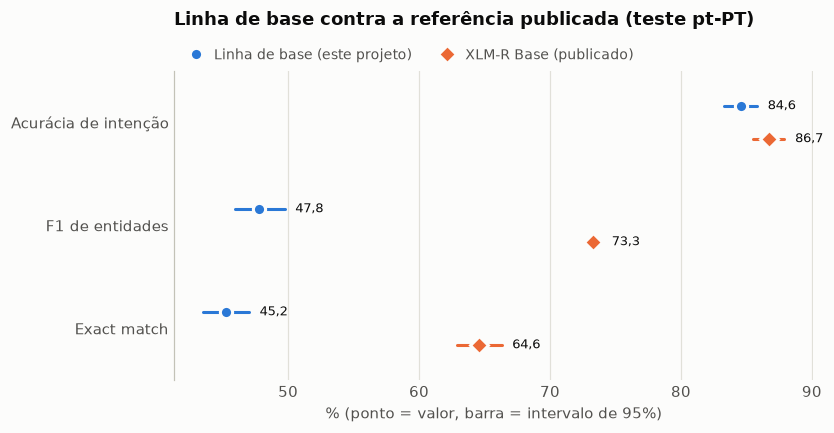


**Leitura.**

- Em **intenção**, um saco de palavras fica a 2,1 pontos de um Transformer pré-treinado de 270 milhões de parâmetros. Classificar a intenção é a parte fácil da tarefa.
- Em **entidades**, a distância é de 25,5 pontos, e ela arrasta o **exact match** (19,4 pontos). É aqui que contexto e arquitetura fazem diferença.
- O alvo da Etapa 3 fica definido: uma rede pequena que feche a distância em entidades sem perder a intenção.


In [16]:
base_teste = no_teste.loc[linha_de_base.nome]
xlmr = massive.REFERENCIA["XLM-R Base"]
tres = {"intent_acc": "Acurácia de intenção", "slot_f1": "F1 de entidades", "exact_match": "Exact match"}

fig, ax = visual.pontos_com_intervalo(
    {
        "Linha de base (este projeto)": {
            nome: (100 * base_teste[m], 100 * base_teste[m + "_ic_min"], 100 * base_teste[m + "_ic_max"])
            for m, nome in tres.items()
        },
        "XLM-R Base (publicado)": {
            nome: (xlmr[m][0], xlmr[m][0] - xlmr[m][1], xlmr[m][0] + xlmr[m][1]) for m, nome in tres.items()
        },
    },
    "Linha de base contra a referência publicada (teste pt-PT)",
    "% (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "teste_contra_referencia")
plt.show()

distancia = {m: xlmr[m][0] - 100 * base_teste[m] for m in tres}
display(Markdown(f"""
**Leitura.**

- Em **intenção**, um saco de palavras fica a {num(distancia['intent_acc'])} pontos de um Transformer pré-treinado de 270 milhões de parâmetros. Classificar a intenção é a parte fácil da tarefa.
- Em **entidades**, a distância é de {num(distancia['slot_f1'])} pontos, e ela arrasta o **exact match** ({num(distancia['exact_match'])} pontos). É aqui que contexto e arquitetura fazem diferença.
- O alvo da Etapa 3 fica definido: uma rede pequena que feche a distância em entidades sem perder a intenção.
"""))

## 10. Entrega

As previsões ficam guardadas: as etapas seguintes comparam os seus modelos com a linha de base, de forma pareada, sem precisar treiná-la de novo.

In [17]:
apelido = {piso.nome: "piso", linha_de_base.nome: "linha_de_base"}
for s in (piso, linha_de_base):
    salvar_previsoes(PASTA / "previsoes" / f"{apelido[s.nome]}_dev.parquet", dev["id"], prev_dev[s.nome])
    salvar_previsoes(PASTA / "previsoes" / f"{apelido[s.nome]}_test.parquet", teste["id"], prev_teste[s.nome])
resultados.salvar(linhas, PASTA)

manifesto = {
    "etapa": "02_avaliacao",
    "gerado_em": date.today().isoformat(),
    "entrada": "entregas/01_dados",
    "metricas": list(qualidade.METRICAS),
    "bootstrap": {"sorteios": 2000, "unidade": "enunciado", "confianca": 0.95, "semente": 0},
    "latencia": {"consultas": eficiencia.CONSULTAS, "aquecimento": eficiencia.AQUECIMENTO, "lote": 1, "fonte_das_consultas": "dev"},
    "linha_de_base": {"escolhida": linha_de_base.nome, "regra": "IC95 da diferença de intent_acc em dev acima de zero"},
    "maquina": maquina,
}
(PASTA / "manifesto.json").write_text(json.dumps(manifesto, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

# Recarrega as previsões do disco e mede de novo: tem de dar o que foi gravado.
ids, relidas = carregar_previsoes(PASTA / "previsoes" / "linha_de_base_test.parquet")
gravado = resultados.carregar(PASTA).query("sistema == @linha_de_base.nome and particao == 'test'").iloc[0]
recarrega_ok = ids == list(teste["id"]) and all(
    abs(v - gravado[m]) < 1e-12 for m, v in qualidade.avaliar(ouro_teste, relidas).items()
)
print("Previsões relidas do disco reproduzem os resultados gravados:", "sim" if recarrega_ok else "NÃO")

Previsões relidas do disco reproduzem os resultados gravados: sim


### Critério de pronto

In [18]:
pronto = pd.Series({
    "Rótulos humanos como previsão tiram nota máxima": oraculo_ok,
    "Régua igual à conta oficial do MASSIVE (diferença < 0,000001)": bool(sem_perda and maior_diferenca < 1e-6),
    "Piso dá o valor previsto pelos dados": piso_ok,
    "Linha de base medida em qualidade e eficiência, e relida do disco": recarrega_ok,
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
Rótulos humanos como previsão tiram nota máxima,sim
"Régua igual à conta oficial do MASSIVE (diferença < 0,000001)",sim
Piso dá o valor previsto pelos dados,sim
"Linha de base medida em qualidade e eficiência, e relida do disco",sim


## 11. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/02_avaliacao/RESUMO.md`.

In [19]:
def linha_md(nome, linha):
    return (f"| {nome} | {pts(linha['intent_acc'])} | {pts(linha['intent_macro_f1'])} | {pts(linha['slot_f1'])} "
            f"| {pts(linha['exact_match'])} | {n(linha['parametros'])} | {num(linha['latencia_p50_ms'], 2)} ms |")


def referencia_md(nome, ref):
    return (f"| {nome} (publicado) | {num(ref['intent_acc'][0])} | n/d | {num(ref['slot_f1'][0])} "
            f"| {num(ref['exact_match'][0])} | {n(ref['parametros'])} | n/d |")


margem_teste = {m: (base_teste[m + "_ic_max"] - base_teste[m + "_ic_min"]) / 2 for m in qualidade.METRICAS}

resumo = f"""# Etapa 2 · Avaliação: resumo da entrega

**Pergunta.** Como saber se um sistema resolve a tarefa, e a que custo?

**Resposta.** Com uma régua de duas faces, a mesma para todos os sistemas do projeto.

- **Qualidade:** acurácia e macro-F1 de intenção, F1 de entidades inteiras e exact match, sempre contra os rótulos humanos, com intervalo de 95% por bootstrap.
- **Eficiência:** latência por consulta (uma por vez, {eficiencia.CONSULTAS} consultas, percentis), parâmetros e tamanho em disco, com a máquina registrada.

A régua foi conferida antes de medir qualquer coisa: dá os mesmos números da conta oficial do MASSIVE (maior diferença: {f"{maior_diferenca:.0e}" if maior_diferenca else "zero"}).

## Resultado no teste (pt-PT, {n(len(teste))} enunciados)

| Sistema | Intenção (acurácia) | Intenção (macro-F1) | Entidades (F1) | Exact match | Parâmetros | Latência p50 |
|---|---|---|---|---|---|---|
{linha_md(piso.nome, no_teste.loc[piso.nome])}
{linha_md(linha_de_base.nome, base_teste)}
{chr(10).join(referencia_md(nome, ref) for nome, ref in massive.REFERENCIA.items())}

Os modelos publicados (FitzGerald et al., Tabelas 7 a 9) treinaram com os 51 idiomas juntos; os deste projeto, só com pt-PT.

![Linha de base contra a referência](figuras/teste_contra_referencia.png)

## O que a régua já mostrou

- **Resolução do teste.** Na linha de base, a margem de 95% é de ±{pts(margem_teste['intent_acc'])} em acurácia de intenção, ±{pts(margem_teste['slot_f1'])} em F1 de entidades e ±{pts(margem_teste['exact_match'])} em exact match. Diferenças menores só aparecem em comparação pareada.
- **Intenção é a parte fácil.** Um saco de palavras fica a {num(distancia['intent_acc'])} pontos do XLM-R publicado em acurácia de intenção.
- **Entidades são a parte difícil.** A distância é de {num(distancia['slot_f1'])} pontos em F1 de entidades e de {num(distancia['exact_match'])} em exact match. É onde a arquitetura da Etapa 3 precisa ganhar.
- **Olhar dentro da palavra ajuda.** Somar n-gramas de caracteres deu {dif(d['diferenca'])} pontos de acurácia de intenção em dev (intervalo de {dif(d['ic_min'])} a {dif(d['ic_max'])}), o que confirma a hipótese da Etapa 1.
- **Classes raras.** As intenções com menos de 100 exemplos de treino têm F1 médio de {pts(pequenas['f1'].mean())} em dev, contra {pts(grandes['f1'].mean())} das demais.

## Regras de avaliação daqui para frente

| Regra | Motivo |
|---|---|
| Decide-se em `dev`, reporta-se em teste | O teste não pode escolher o modelo que ele mesmo avalia |
| A regra de decisão é escrita antes do resultado | Evita escolher a métrica que favorece a resposta desejada |
| Toda comparação entre dois sistemas é pareada | Enxerga diferenças menores que a margem de cada sistema |
| Todo resultado traz intervalo de 95% | Um número sem margem não diz se a diferença é real |
| Latência sempre com o mesmo protocolo e a máquina registrada | Tempo sem máquina e sem cenário não é comparável |

## Limites

- O bootstrap mede a incerteza do conjunto de teste, não a do treino. Para modelos treinados, a variação entre sementes entra a partir da Etapa 4.
- A latência foi medida dentro do WSL2 ({maquina['cpu']}), sem garantia de fixar o processo nos núcleos de desempenho.
- A referência publicada usa treino multilíngue; a comparação com ela é de ordem de grandeza, não de igual para igual.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `resultados.csv` | Uma linha por sistema e partição: métricas, intervalos, latência, parâmetros, máquina |
| `previsoes/` | As respostas do piso e da linha de base em dev e teste |
| `manifesto.json` | Protocolo usado: sorteios do bootstrap, consultas de latência, regra de decisão |
| `figuras/` | Os gráficos deste notebook |
| `02_avaliacao.html` | Este notebook executado, para leitura |

Para avaliar um sistema novo nas próximas etapas:

```python
from especialista.avaliacao import qualidade, eficiencia, resultados
from especialista.avaliacao.previsao import ouro

prev = sistema.prever(list(dev["utt"]))
qualidade.intervalo(ouro(dev), prev)             # métricas com intervalo
qualidade.comparar(ouro(dev), prev_base, prev)   # contra a linha de base, pareado
eficiencia.medir_latencia(sistema, list(dev["utt"]))
```
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 2 · Avaliação: resumo da entrega

**Pergunta.** Como saber se um sistema resolve a tarefa, e a que custo?

**Resposta.** Com uma régua de duas faces, a mesma para todos os sistemas do projeto.

- **Qualidade:** acurácia e macro-F1 de intenção, F1 de entidades inteiras e exact match, sempre contra os rótulos humanos, com intervalo de 95% por bootstrap.
- **Eficiência:** latência por consulta (uma por vez, 1024 consultas, percentis), parâmetros e tamanho em disco, com a máquina registrada.

A régua foi conferida antes de medir qualquer coisa: dá os mesmos números da conta oficial do MASSIVE (maior diferença: 6e-17).

## Resultado no teste (pt-PT, 2.974 enunciados)

| Sistema | Intenção (acurácia) | Intenção (macro-F1) | Entidades (F1) | Exact match | Parâmetros | Latência p50 |
|---|---|---|---|---|---|---|
| Piso (classe majoritária) | 7,0 | 0,2 | 0,0 | 1,2 | 1 | 0,00 ms |
| Linha de base (palavras + caracteres) | 84,6 | 81,4 | 47,8 | 45,2 | 3.940.300 | 0,82 ms |
| XLM-R Base (publicado) | 86,7 | n/d | 73,3 | 64,6 | 270.000.000 | n/d |
| mT5 Base (encoder) (publicado) | 86,9 | n/d | 74,9 | 66,0 | 258.000.000 | n/d |
| mT5 Base (texto para texto) (publicado) | 86,7 | n/d | 76,6 | 67,6 | 580.000.000 | n/d |

Os modelos publicados (FitzGerald et al., Tabelas 7 a 9) treinaram com os 51 idiomas juntos; os deste projeto, só com pt-PT.

![Linha de base contra a referência](figuras/teste_contra_referencia.png)

## O que a régua já mostrou

- **Resolução do teste.** Na linha de base, a margem de 95% é de ±1,2 em acurácia de intenção, ±1,9 em F1 de entidades e ±1,7 em exact match. Diferenças menores só aparecem em comparação pareada.
- **Intenção é a parte fácil.** Um saco de palavras fica a 2,1 pontos do XLM-R publicado em acurácia de intenção.
- **Entidades são a parte difícil.** A distância é de 25,5 pontos em F1 de entidades e de 19,4 em exact match. É onde a arquitetura da Etapa 3 precisa ganhar.
- **Olhar dentro da palavra ajuda.** Somar n-gramas de caracteres deu +2,5 pontos de acurácia de intenção em dev (intervalo de +1,5 a +3,4), o que confirma a hipótese da Etapa 1.
- **Classes raras.** As intenções com menos de 100 exemplos de treino têm F1 médio de 73,1 em dev, contra 85,6 das demais.

## Regras de avaliação daqui para frente

| Regra | Motivo |
|---|---|
| Decide-se em `dev`, reporta-se em teste | O teste não pode escolher o modelo que ele mesmo avalia |
| A regra de decisão é escrita antes do resultado | Evita escolher a métrica que favorece a resposta desejada |
| Toda comparação entre dois sistemas é pareada | Enxerga diferenças menores que a margem de cada sistema |
| Todo resultado traz intervalo de 95% | Um número sem margem não diz se a diferença é real |
| Latência sempre com o mesmo protocolo e a máquina registrada | Tempo sem máquina e sem cenário não é comparável |

## Limites

- O bootstrap mede a incerteza do conjunto de teste, não a do treino. Para modelos treinados, a variação entre sementes entra a partir da Etapa 4.
- A latência foi medida dentro do WSL2 (13th Gen Intel(R) Core(TM) i7-13700K), sem garantia de fixar o processo nos núcleos de desempenho.
- A referência publicada usa treino multilíngue; a comparação com ela é de ordem de grandeza, não de igual para igual.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `resultados.csv` | Uma linha por sistema e partição: métricas, intervalos, latência, parâmetros, máquina |
| `previsoes/` | As respostas do piso e da linha de base em dev e teste |
| `manifesto.json` | Protocolo usado: sorteios do bootstrap, consultas de latência, regra de decisão |
| `figuras/` | Os gráficos deste notebook |
| `02_avaliacao.html` | Este notebook executado, para leitura |

Para avaliar um sistema novo nas próximas etapas:

```python
from especialista.avaliacao import qualidade, eficiencia, resultados
from especialista.avaliacao.previsao import ouro

prev = sistema.prever(list(dev["utt"]))
qualidade.intervalo(ouro(dev), prev)             # métricas com intervalo
qualidade.comparar(ouro(dev), prev_base, prev)   # contra a linha de base, pareado
eficiencia.medir_latencia(sistema, list(dev["utt"]))
```


In [20]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/02_avaliacao/RESUMO.md,4.1
entregas/02_avaliacao/figuras/bootstrap.png,30.0
entregas/02_avaliacao/figuras/decisao_caracteres.png,38.6
entregas/02_avaliacao/figuras/f1_por_intencao.png,50.6
entregas/02_avaliacao/figuras/latencia.png,32.2
entregas/02_avaliacao/figuras/teste_contra_referencia.png,51.6
entregas/02_avaliacao/manifesto.json,0.7
entregas/02_avaliacao/previsoes/linha_de_base_dev.parquet,24.0
entregas/02_avaliacao/previsoes/linha_de_base_test.parquet,34.0
entregas/02_avaliacao/previsoes/piso_dev.parquet,12.3
